## 🔗 Live Deployment Link: https://olympic-athletes-model-fatimahnaeem15-cyber.streamlit.app

# Predicting How Many Olympics an Athlete Will Take Part In
### Comparing 5 ML algorithms with 10-Fold Cross-Validation

**Course:** Machine Learning Fundamentals (AIC354) | **Assignment 3, Task 2**

**Problem:** Predict `games_participations`, the number of Olympic Games an athlete took part in (from 1 to 10). This is a regression problem, like the Car Price Prediction System.

**Dataset:** `olympic_athletes.csv` (75,904 Olympic athletes, scraped from olympics.com). I use the **full dataset**.

**Algorithms (none of them are used in the car price notebooks):**
1. Elastic Net
2. Bayesian Ridge
3. Huber Regressor
4. Bagging Regressor
5. MLP Regressor (neural network)

**Metric:** RMSE (Root Mean Square Error), lower is better.

## Step 1: Import libraries

In [1]:
import os
import pickle
import re
import time

import numpy as np
import pandas as pd

import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# The 5 regression algorithms (different from the car price notebooks)
from sklearn.linear_model import ElasticNet, BayesianRidge, HuberRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor

import matplotlib.pyplot as plt
from tqdm import tqdm

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("scikit-learn version:", sklearn.__version__)
print("(Write this version in requirements.txt of the web app so the model loads without errors)")

scikit-learn version: 1.9.1
(Write this version in requirements.txt of the web app so the model loads without errors)


## Step 2: Upload the dataset (Google Colab)

In [2]:
DATA_FILE = "olympic_athletes.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Run this cell again and upload it.")

'olympic_athletes.csv' is ready.


## Step 3: Load and explore the data

In [3]:
raw = pd.read_csv(DATA_FILE)
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (75904, 7)


,athlete_url,athlete_full_name,games_participations,first_game,athlete_year_birth,athlete_medals,bio
0,https://olympics.com/en/athletes/cooper-woods-...,Cooper WOODS-TOPALOVIC,1,Beijing 2022,"2,000.000",NaN,NaN
1,https://olympics.com/en/athletes/elofsson,Felix ELOFSSON,2,PyeongChang 2018,"1,995.000",NaN,NaN
2,https://olympics.com/en/athletes/dylan-walczyk,Dylan WALCZYK,1,Beijing 2022,"1,993.000",NaN,NaN
3,https://olympics.com/en/athletes/olli-penttala,Olli PENTTALA,1,Beijing 2022,"1,995.000",NaN,NaN
4,https://olympics.com/en/athletes/reikherd,Dmitriy REIKHERD,1,Beijing 2022,"1,989.000",NaN,NaN


In [4]:
print("Missing values per column:")
print(raw.isna().sum())
print()
print("How many Games did athletes take part in?")
print(raw["games_participations"].value_counts().sort_index())

Missing values per column:
athlete_url                 0
athlete_full_name           0
games_participations        0
first_game                 22
athlete_year_birth       2456
athlete_medals          60552
bio                     53062
dtype: int64

How many Games did athletes take part in?
games_participations
0        22
1     48328
2     18171
3      6624
4      2014
5       558
6       137
7        36
8        10
9         3
10        1
Name: count, dtype: int64


## Step 4: Data cleaning and feature creation

The raw file has mostly text columns, so I create numeric features from them:

* `first_game_year`: the year taken from the `first_game` text (for example "Rio 2016" gives 2016)
* `season`: Winter or Summer (taken from the `first_game` text)
* `birth_year`: from `athlete_year_birth`
* `age_at_first_game`: first game year minus birth year
* `gold`, `silver`, `bronze`: medal counts read from the messy `athlete_medals` text (G, S, B). Athletes with no medals get 0.
* `has_bio`: 1 if the athlete has a biography, otherwise 0

The columns `athlete_url`, `athlete_full_name` and `bio` are identifiers or free text, so they are not used directly.
Missing birth years and first game years are filled inside the pipeline, so **no rows are deleted** and the full dataset is used.

In [5]:
df = raw.copy()

# year and season from text like "Beijing 2022" / "Lillehammer 1994 Winter"
df["first_game_year"] = df["first_game"].str.extract(r"(\d{4})")[0].astype(float)
df["season"] = np.where(df["first_game"].fillna("").str.contains("Winter"), "Winter", "Summer")

df["birth_year"] = df["athlete_year_birth"]
df["age_at_first_game"] = df["first_game_year"] - df["birth_year"]

# medal text looks like "\n\n\n1\n\nG\n\n\n\n2\n\nB\n\n"  (number then letter)
def count_medals(text, letter):
    if not isinstance(text, str):
        return 0
    found = re.findall(r"(\d+)\s*" + letter + r"(?![A-Za-z])", text)
    return sum(int(n) for n in found)

df["gold"] = df["athlete_medals"].apply(lambda t: count_medals(t, "G"))
df["silver"] = df["athlete_medals"].apply(lambda t: count_medals(t, "S"))
df["bronze"] = df["athlete_medals"].apply(lambda t: count_medals(t, "B"))

df["has_bio"] = (df["bio"].fillna("").str.strip().str.len() > 5).astype(int)

categorical_cols = ["season"]
numeric_cols = ["first_game_year", "birth_year", "age_at_first_game", "gold", "silver", "bronze", "has_bio"]
target_col = "games_participations"

X = df[categorical_cols + numeric_cols]
y = df[target_col].values

print("Rows used:", len(X))
print("Total medals found -> gold:", df["gold"].sum(), "| silver:", df["silver"].sum(), "| bronze:", df["bronze"].sum())
X.head()

Rows used: 75904
Total medals found -> gold: 8349 | silver: 8034 | bronze: 8341


,season,first_game_year,birth_year,age_at_first_game,gold,silver,bronze,has_bio
0,Summer,"2,022.000","2,000.000",22.000,0,0,0,0
1,Summer,"2,018.000","1,995.000",23.000,0,0,0,0
2,Summer,"2,022.000","1,993.000",29.000,0,0,0,0
3,Summer,"2,022.000","1,995.000",27.000,0,0,0,0
4,Summer,"2,022.000","1,989.000",33.000,0,0,0,0


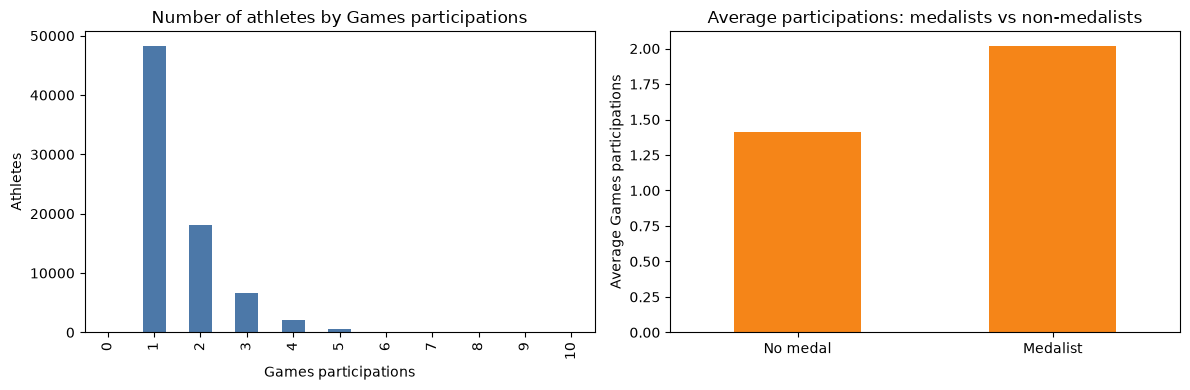

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
raw["games_participations"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#4C78A8")
ax[0].set_title("Number of athletes by Games participations")
ax[0].set_xlabel("Games participations")
ax[0].set_ylabel("Athletes")

df.groupby(df["gold"] + df["silver"] + df["bronze"] > 0)["games_participations"].mean().plot(
    kind="bar", ax=ax[1], color="#F58518")
ax[1].set_xticklabels(["No medal", "Medalist"], rotation=0)
ax[1].set_title("Average participations: medalists vs non-medalists")
ax[1].set_ylabel("Average Games participations")
plt.tight_layout()
plt.show()

## Step 5: Preprocessing pipeline

Numbers: fill missing values with the median, then scale them (needed for Elastic Net, Huber, Bayesian Ridge and the neural network).
Category (season): one-hot encoding.
Everything is inside a `Pipeline`, so in every fold the preprocessing is learned **only from the training part**. This avoids data leakage.

In [7]:
preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])
print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


## Step 6: Choose the 5 algorithms

In [8]:
algorithms = {
    "Elastic Net": ElasticNet(alpha=0.01, l1_ratio=0.5),
    "Bayesian Ridge": BayesianRidge(),
    "Huber Regressor": HuberRegressor(max_iter=300),
    "Bagging Regressor": BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=8), n_estimators=50, random_state=42),
    "MLP Neural Network": MLPRegressor(
        hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=42),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Elastic Net
  2. Bayesian Ridge
  3. Huber Regressor
  4. Bagging Regressor
  5. MLP Neural Network


## Step 7: 10-Fold Cross-Validation on the FULL dataset

In [9]:
N_FOLDS = 10
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

fold_rmse = {name: [] for name in algorithms}
train_time = {name: 0.0 for name in algorithms}

progress = tqdm(total=len(algorithms) * N_FOLDS, desc="Cross-validation", unit="fold")

for name, model in algorithms.items():
    for fold_number, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        pipe = Pipeline([("prep", clone(preprocessor)), ("model", clone(model))])

        start = time.time()
        pipe.fit(X_train, y_train)
        train_time[name] += time.time() - start

        predictions = pipe.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        fold_rmse[name].append(rmse)

        progress.set_postfix(model=name, fold=fold_number)
        progress.update(1)

progress.close()
print("Cross-validation finished.")

Cross-validation: 100%|██████████| 50/50 [02:17<00:00,  2.76s/fold, fold=10, model=MLP Neural Network]

Cross-validation finished.


## Step 8: Results table

In [10]:
# For comparison: a "model" that always predicts the average number of participations
baseline_rmse = float(np.std(y))
print(f"Baseline RMSE (always predict the average): {baseline_rmse:.3f}")

results = pd.DataFrame({
    "Algorithm": list(algorithms.keys()),
    "Mean RMSE": [np.mean(fold_rmse[n]) for n in algorithms],
    "Std of RMSE": [np.std(fold_rmse[n]) for n in algorithms],
    "Best Fold RMSE": [np.min(fold_rmse[n]) for n in algorithms],
    "Worst Fold RMSE": [np.max(fold_rmse[n]) for n in algorithms],
    "Total Train Time (s)": [train_time[n] for n in algorithms],
}).sort_values("Mean RMSE").reset_index(drop=True)
results.index = results.index + 1
results.index.name = "Rank"
results

Baseline RMSE (always predict the average): 0.855


,Algorithm,Mean RMSE,Std of RMSE,Best Fold RMSE,Worst Fold RMSE,Total Train Time (s)
Rank,,,,,,
1,MLP Neural Network,0.749,0.009,0.736,0.768,101.267
2,Bagging Regressor,0.750,0.009,0.736,0.770,29.998
3,Bayesian Ridge,0.784,0.011,0.766,0.808,1.054
4,Elastic Net,0.784,0.011,0.766,0.809,1.585
5,Huber Regressor,0.821,0.015,0.797,0.853,2.723


In [11]:
fold_table = pd.DataFrame(fold_rmse, index=[f"Fold {i}" for i in range(1, N_FOLDS + 1)])
fold_table

,Elastic Net,Bayesian Ridge,Huber Regressor,Bagging Regressor,MLP Neural Network
Fold 1,0.783,0.782,0.818,0.750,0.751
Fold 2,0.794,0.793,0.830,0.760,0.757
Fold 3,0.783,0.782,0.821,0.742,0.741
Fold 4,0.777,0.776,0.813,0.744,0.742
Fold 5,0.766,0.766,0.797,0.736,0.736
Fold 6,0.781,0.781,0.817,0.745,0.745
Fold 7,0.773,0.773,0.804,0.745,0.744
Fold 8,0.793,0.792,0.831,0.758,0.759
Fold 9,0.785,0.784,0.821,0.752,0.752
Fold 10,0.809,0.808,0.853,0.770,0.768


## Step 9: Charts

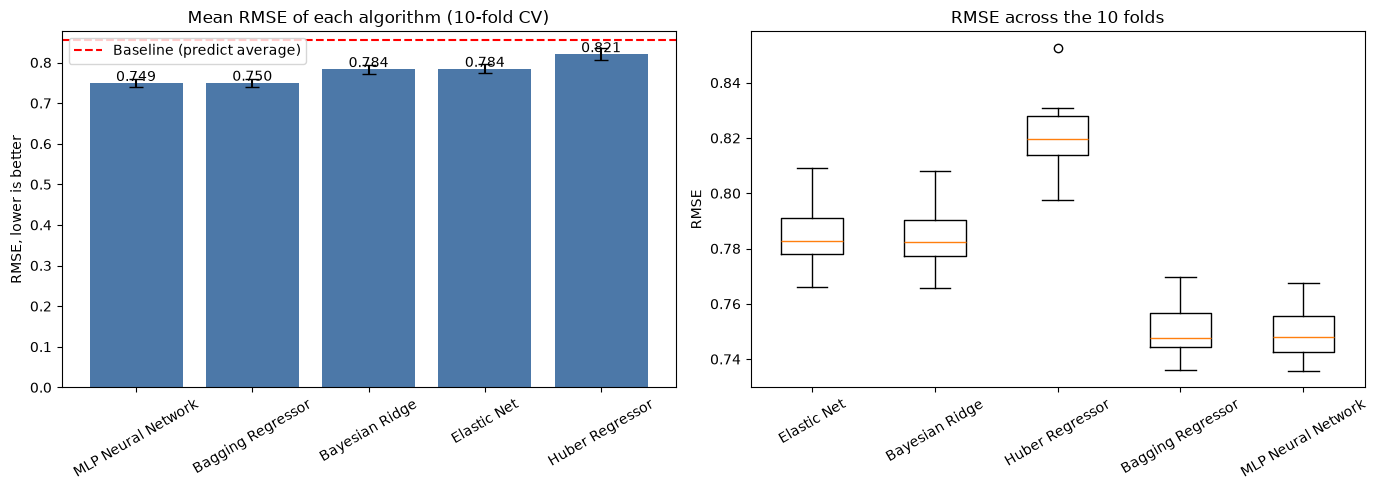

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ordered = results.sort_values("Mean RMSE")
ax[0].bar(ordered["Algorithm"], ordered["Mean RMSE"], yerr=ordered["Std of RMSE"],
          capsize=5, color="#4C78A8")
ax[0].axhline(baseline_rmse, color="red", linestyle="--", label="Baseline (predict average)")
ax[0].set_title("Mean RMSE of each algorithm (10-fold CV)")
ax[0].set_ylabel("RMSE, lower is better")
ax[0].tick_params(axis="x", rotation=30)
ax[0].legend()
for i, v in enumerate(ordered["Mean RMSE"]):
    ax[0].text(i, v + 0.005, f"{v:.3f}", ha="center")

ax[1].boxplot([fold_rmse[n] for n in algorithms])
ax[1].set_xticklabels(list(algorithms.keys()))
ax[1].set_title("RMSE across the 10 folds")
ax[1].set_ylabel("RMSE")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

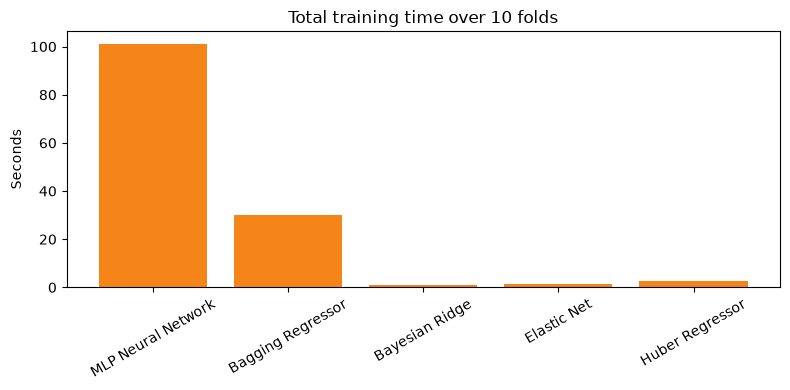

In [14]:
plt.figure(figsize=(8, 4))
plt.bar(results["Algorithm"], results["Total Train Time (s)"], color="#F58518")
plt.title("Total training time over 10 folds")
plt.ylabel("Seconds")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 10: Train the best model on all the data and save it

In [15]:
best_name = results.iloc[0]["Algorithm"]
print("Best algorithm (lowest mean RMSE):", best_name)

final_model = Pipeline([("prep", clone(preprocessor)), ("model", clone(algorithms[best_name]))])
final_model.fit(X, y)

bundle = {
    "model": final_model,
    "model_name": best_name,
    "cv_rmse": float(results.iloc[0]["Mean RMSE"]),
    "baseline_rmse": baseline_rmse,
    "feature_columns": categorical_cols + numeric_cols,
    "sklearn_version": sklearn.__version__,
}

MODEL_FILE = "olympic_participation_model.pkl"
with open(MODEL_FILE, "wb") as f:
    pickle.dump(bundle, f)
print(f"Saved '{MODEL_FILE}' ({os.path.getsize(MODEL_FILE) / 1e6:.2f} MB)")

Best algorithm (lowest mean RMSE): MLP Neural Network
Saved 'olympic_participation_model.pkl' (0.08 MB)


In [16]:
# Quick test: reload the saved file and predict one example athlete
with open(MODEL_FILE, "rb") as f:
    loaded = pickle.load(f)

example = pd.DataFrame([{
    "season": "Summer", "first_game_year": 2008, "birth_year": 1985,
    "age_at_first_game": 23, "gold": 1, "silver": 0, "bronze": 1, "has_bio": 1,
}])[loaded["feature_columns"]]
print(f"Predicted Games participations: {loaded['model'].predict(example)[0]:.2f}")

Predicted Games participations: 2.46


In [17]:
# Download the model file to your computer (works in Google Colab)
if IN_COLAB:
    files.download(MODEL_FILE)

# CONCLUSION
In this assignment I compared 5 algorithms (Elastic Net, Bayesian Ridge, Huber Regressor, Bagging Regressor and an MLP neural network) on the full Olympic athletes dataset of 75,904 rows. I used 10-fold cross-validation to predict how many Olympic Games an athlete takes part in. The MLP Neural Network gave the lowest mean RMSE of about 0.749, so I selected it as the best model. The Bagging Regressor was almost the same at 0.750. Bayesian Ridge and Elastic Net both gave about 0.784, and Huber Regressor was the worst at about 0.821.

The two non-linear models did better than the linear ones because the relationship between age, medals and the number of Games is not a straight line. However, the improvement was small. A model that always predicts the average gives an RMSE of about 0.855, so the best model is only about 12% better than that. The error is still fairly high because most athletes (about 63%) took part only once, and the dataset has very few useful columns. It has mostly names, links and text, so there is limited information to predict from.

The linear models trained the fastest, in about 1 to 3 seconds in total. Bagging took about 27 seconds and the MLP took about 96 seconds. Since the MLP and Bagging were almost tied in RMSE, Bagging is the more practical choice because it trains much faster. I still deployed the model with the lowest RMSE, the MLP, as a Streamlit web app.